In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import KBinsDiscretizer

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Cargar el dataset y seleccionar solo las columnas continuas necesarias
df = pd.read_parquet("../data/dataset_5M.parquet")
X = df[["edad", "altura", "ingresos"]]

print("Dimensiones de X:", X.shape)

Dimensiones de X: (5000000, 3)


In [3]:
discretizador_uniforme = KBinsDiscretizer(
    n_bins=10,
    encode="ordinal",
    strategy="uniform"
)

inicio = time.perf_counter()
X_uniforme = discretizador_uniforme.fit_transform(X)
fin = time.perf_counter()

tiempo_uniforme = fin - inicio
print(f"Tiempo uniform: {tiempo_uniforme:.4f} segundos")

Tiempo uniform: 0.3874 segundos


In [4]:
print("Primeros 10 registros transformados (bins):")
print(X_uniforme[:10])

print("\nLímites de los bins (bin_edges_):")
print(discretizador_uniforme.bin_edges_)

Primeros 10 registros transformados (bins):
[[5. 3. 0.]
 [4. 5. 1.]
 [5. 4. 1.]
 [6. 3. 1.]
 [4. 1. 1.]
 [4. 3. 0.]
 [6. 5. 1.]
 [5. 6. 1.]
 [4. 3. 1.]
 [5. 4. 0.]]

Límites de los bins (bin_edges_):
[array([-13.4033074 ,  -2.44823774,   8.50683192,  19.46190158,
         30.41697124,  41.3720409 ,  52.32711056,  63.28218022,
         74.23724988,  85.19231954,  96.1473892 ])
 array([126.06368911, 135.18889325, 144.3140974 , 153.43930154,
        162.56450568, 171.68970982, 180.81491397, 189.94011811,
        199.06532225, 208.19052639, 217.31573054])
 array([  2203.30239177,  20784.87600015,  39366.44960852,  57948.0232169 ,
         76529.59682528,  95111.17043365, 113692.74404203, 132274.3176504 ,
        150855.89125878, 169437.46486716, 188019.03847553])                ]


In [5]:
discretizador_quantile = KBinsDiscretizer(
    n_bins=10,
    encode="ordinal",
    strategy="quantile",
    random_state=42
)

inicio = time.perf_counter()
X_quantile = discretizador_quantile.fit_transform(X)
fin = time.perf_counter()

tiempo_quantile = fin - inicio
print(f"Tiempo quantile: {tiempo_quantile:.4f} segundos")

Tiempo quantile: 0.4418 segundos


In [6]:
discretizador_kmeans = KBinsDiscretizer(
    n_bins=10,
    encode="ordinal",
    strategy="kmeans",
    random_state=42
)

inicio = time.perf_counter()
X_kmeans = discretizador_kmeans.fit_transform(X)
fin = time.perf_counter()

tiempo_kmeans = fin - inicio
print(f"Tiempo kmeans: {tiempo_kmeans:.4f} segundos")

Tiempo kmeans: 1.0409 segundos


In [7]:
comparacion_sklearn = pd.DataFrame({
    "estrategia": ["uniform", "quantile", "kmeans"],
    "tiempo": [tiempo_uniforme, tiempo_quantile, tiempo_kmeans]
})

comparacion_sklearn.to_csv("../resultados/tablas/sklearn_estrategias.csv", index=False)
comparacion_sklearn

,estrategia,tiempo
0,uniform,0.387415
1,quantile,0.441787
2,kmeans,1.040914


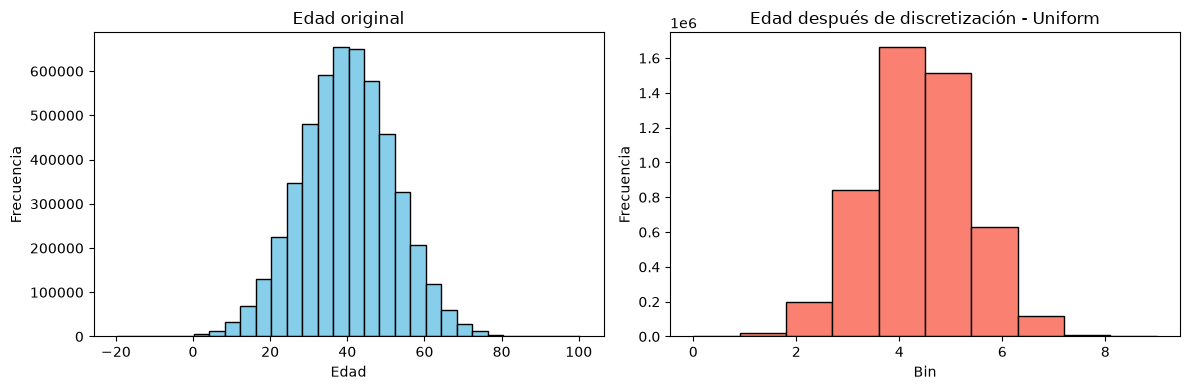

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df["edad"], bins=30, color="skyblue", edgecolor="black")
plt.title("Edad original")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")

plt.subplot(1, 2, 2)
plt.hist(X_uniforme[:, 0], bins=10, color="salmon", edgecolor="black")
plt.title("Edad después de discretización - Uniform")
plt.xlabel("Bin")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.savefig("../resultados/graficos/sklearn_comparacion_edad.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
print("Valores únicos en edad original:", df["edad"].nunique())
print("Valores únicos en edad discretizada:", np.unique(X_uniforme[:, 0]))

# Calcular distribución de registros por bin en quantile
valores, cantidades = np.unique(X_quantile[:, 0], return_counts=True)
tabla_bins = pd.DataFrame({
    "bin": valores,
    "cantidad": cantidades
})

tabla_bins.to_csv("../resultados/tablas/sklearn_bins_quantile.csv", index=False)
tabla_bins

Valores únicos en edad original: 5000000
Valores únicos en edad discretizada: [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]


,bin,cantidad
0,0.0,498712
1,1.0,502090
2,2.0,496643
3,3.0,497865
4,4.0,494028
5,5.0,502077
6,6.0,502735
7,7.0,502389
8,8.0,501614
9,9.0,501847
